
# Тест 01: Supervised  learning (Обучение с учителем)

Этот тест предназначен для оценки ваших знаний об импорте данных, их визуализации и использовании моделей машинного обучения.
Пожалуйста, введите ответы непосредственно в ячейки, предназначенные для каждого раздела.


## 1. Импорт данных
    1. Импортируйте библиотеку `pandas` и загрузите файл `Human_Activity_Recognition_Using_Smartphones_Data.csv`.
    2. Проверьте размерности и типы данных.
    3. Выведите первые 5 строк DataFrame и проверьте наличие пропущенных значений.


In [214]:
# 1.0 Подготовка: собираем CSV-файл из исходных файлов архива (выполняется один раз)
import os
import pandas as pd

if not os.path.exists("Human_Activity_Recognition_Using_Smartphones_Data.csv"):
    raw = "UCI HAR Dataset"

    # читаем названия 561 признака
    names = pd.read_csv(f"{raw}/features.txt", sep=r"\s+", header=None)[1]

    # делаем повторяющиеся названия уникальными
    seen, columns = {}, []
    for n in names:
        k = seen.get(n, 0)
        seen[n] = k + 1
        columns.append(n if k == 0 else f"{n}_{k}")

    # читаем названия активностей (1 -> WALKING и т.д.)
    labels = pd.read_csv(f"{raw}/activity_labels.txt", sep=r"\s+", header=None, index_col=0)[1]

    # объединяем признаки и активности для train и test
    parts = []
    for part in ["train", "test"]:
        X = pd.read_csv(f"{raw}/{part}/X_{part}.txt", sep=r"\s+", header=None, names=columns)
        y = pd.read_csv(f"{raw}/{part}/y_{part}.txt", header=None)[0]
        X["Activity"] = y.map(labels).values
        parts.append(X)

    # сохраняем всё в один CSV-файл
    pd.concat(parts, ignore_index=True).to_csv(
        "Human_Activity_Recognition_Using_Smartphones_Data.csv", index=False)

In [215]:
# 1.1 Импортируем pandas и загружаем данные из CSV-файла
import pandas as pd

df = pd.read_csv("Human_Activity_Recognition_Using_Smartphones_Data.csv")

In [216]:
# 1.2 Проверяем размерность (строки, столбцы) и типы данных
print("Размерность:", df.shape)
print(df.dtypes)

Размерность: (10299, 562)
tBodyAcc-mean()-X                       float64
tBodyAcc-mean()-Y                       float64
tBodyAcc-mean()-Z                       float64
tBodyAcc-std()-X                        float64
tBodyAcc-std()-Y                        float64
                                         ...   
angle(tBodyGyroJerkMean,gravityMean)    float64
angle(X,gravityMean)                    float64
angle(Y,gravityMean)                    float64
angle(Z,gravityMean)                    float64
Activity                                    str
Length: 562, dtype: object


In [217]:
# 1.3 Выводим первые 5 строк DataFrame
df.head()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,STANDING


In [218]:
# 1.4 Проверяем наличие пропущенных значений
print("Пропущенных значений:", df.isnull().sum().sum())

Пропущенных значений: 0



## 2. Визуализация данных с помощью Matplotlib и Seaborn
1. Создайте точечную диаграмму (scatter plot) для отображения связи между двумя числовыми столбцами.
2. Используйте Seaborn для создания тепловой карты (heatmap) корреляций между столбцами.

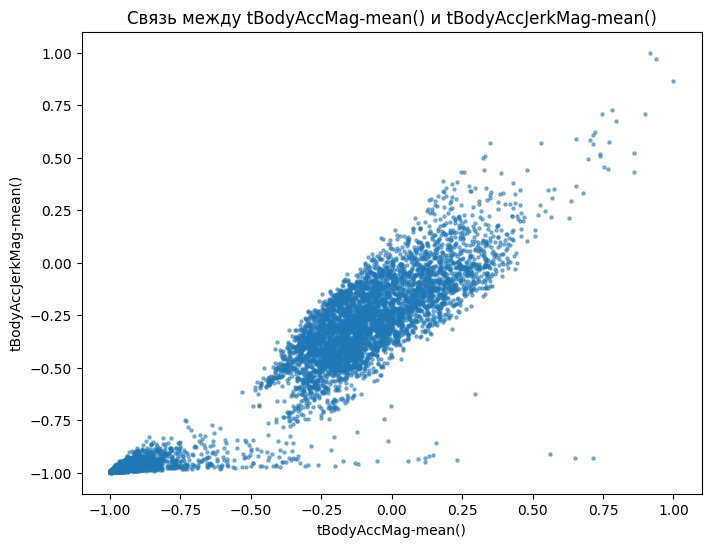

In [219]:
# 2.1 Строим точечную диаграмму (scatter plot) для двух числовых столбцов
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(df["tBodyAccMag-mean()"], df["tBodyAccJerkMag-mean()"], s=5, alpha=0.5)
plt.xlabel("tBodyAccMag-mean()")
plt.ylabel("tBodyAccJerkMag-mean()")
plt.title("Связь между tBodyAccMag-mean() и tBodyAccJerkMag-mean()")
plt.show()

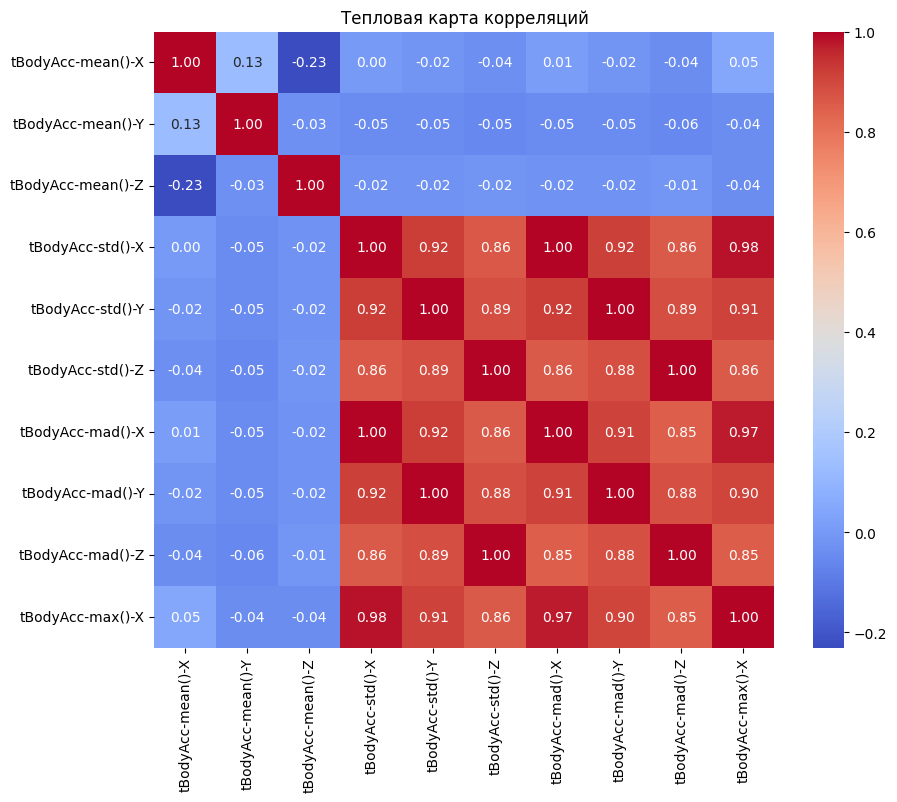

In [220]:
# 2.2 Строим тепловую карту (heatmap) корреляций между столбцами с помощью Seaborn
import seaborn as sns

cols = df.columns[:10]
corr = df[cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Тепловая карта корреляций")
plt.show()

## 3. Метрики ошибки
1. Разделите набор данных на обучающую и тестовую выборки (80%-20%).
2. Постройте модель линейной регрессии на числовых данных.
3. Оцените производительность модели с использованием **MAE**, **MSE** и **RMSE**.

In [221]:
# 3.1 Разделяем данные на обучающую и тестовую выборки (80% / 20%)
from sklearn.model_selection import train_test_split

X = df[["tBodyAcc-std()-X", "tBodyAcc-std()-Y", "tBodyAcc-std()-Z",
        "tBodyGyro-std()-X", "tBodyGyro-std()-Y", "tBodyGyro-std()-Z"]]
y = df["tBodyAccMag-mean()"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (8239, 6) | Test: (2060, 6)


In [222]:
# 3.2 Строим модель линейной регрессии
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [223]:
# 3.3 Оцениваем модель с помощью MAE, MSE и RMSE
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("MAE: ", round(mae, 4))
print("MSE: ", round(mse, 4))
print("RMSE:", round(rmse, 4))

MAE:  0.0163
MSE:  0.0017
RMSE: 0.0413



## 4. Перекрёстная проверка (Cross Validation)
1. Импортируйте библиотеку `scikit-learn`.
2. Разделите набор данных на обучающую и тестовую выборки (80%-20%).
3. Используйте `cross_val_score` для оценки производительности модели KNN на наборе данных.


In [224]:
# 4.1 Импортируем библиотеку scikit-learn
import sklearn
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier

In [225]:
# 4.2 Разделяем данные на обучающую и тестовую выборки (80% / 20%)
X = df.drop(columns="Activity")
y = df["Activity"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (8239, 561) | Test: (2060, 561)


In [226]:
# 4.3 Оцениваем модель KNN с помощью cross_val_score
knn = KNeighborsClassifier(n_neighbors=5)

scores = cross_val_score(knn, X_train, y_train, cv=5, scoring="accuracy")

print("Accuracy по фолдам:", scores.round(4))
print("Средняя accuracy:", round(scores.mean(), 4))

Accuracy по фолдам: [0.9672 0.9563 0.9563 0.9654 0.9624]
Средняя accuracy: 0.9615



## 5. Модели машинного обучения
1. **Линейная регрессия**: Обучите модель линейной регрессии и оцените ее производительность на тестовой выборке.
2. **Логистическая регрессия**: Постройте логистическую модель для задачи бинарной классификации.
3. **SVM**: Обучите модель SVM и протестируйте ее на наборе данных.

In [227]:
# 5.1 Линейная регрессия: обучаем модель и оцениваем её на тестовой выборке
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

X_reg = df[["tBodyAcc-std()-X", "tBodyAcc-std()-Y", "tBodyAcc-std()-Z",
            "tBodyGyro-std()-X", "tBodyGyro-std()-Y", "tBodyGyro-std()-Z"]]
y_reg = df["tBodyAccMag-mean()"]

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42)

lin_model = LinearRegression()
lin_model.fit(X_reg_train, y_reg_train)
y_reg_pred = lin_model.predict(X_reg_test)

print("R^2: ", round(r2_score(y_reg_test, y_reg_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_reg_test, y_reg_pred)), 4))

R^2:  0.9922
RMSE: 0.0413


In [228]:
# 5.2 Логистическая регрессия: бинарная классификация
# 1 — динамическая активность (ходьба), 0 — статическая (сидит, стоит, лежит)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

dynamic = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS"]
y_train_bin = y_train.isin(dynamic).astype(int)
y_test_bin = y_test.isin(dynamic).astype(int)

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train, y_train_bin)
y_pred_bin = log_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test_bin, y_pred_bin), 4))

Accuracy: 1.0


In [229]:
# 5.3 SVM: обучаем модель и тестируем её
from sklearn.svm import SVC

svm_model = SVC()
svm_model.fit(X_train, y_train)
y_pred_svm = svm_model.predict(X_test)

print("Accuracy SVM:", round(accuracy_score(y_test, y_pred_svm), 4))

Accuracy SVM: 0.9723


## 6. Матрица ошибок (Confusion Matrix)
1. Постройте модель логистической классификации.
2. Создайте матрицу ошибок и отобразите ее графически с помощью Seaborn.

In [230]:
# 6.1 Строим модель логистической классификации (все 6 активностей)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

log_multi = LogisticRegression(max_iter=1000)
log_multi.fit(X_train, y_train)
y_pred_log = log_multi.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred_log), 4))

Accuracy: 0.985


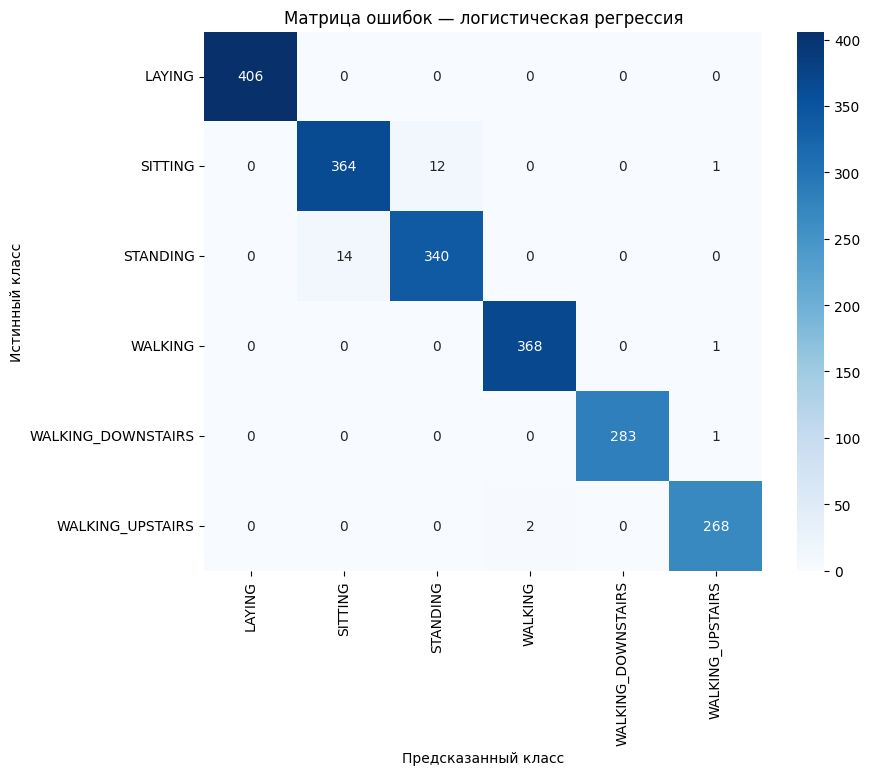

In [231]:
# 6.2 Создаём матрицу ошибок и отображаем её с помощью Seaborn
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_log, labels=log_multi.classes_)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=log_multi.classes_, yticklabels=log_multi.classes_)
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.title("Матрица ошибок — логистическая регрессия")
plt.show()


## 7. Градиентный спуск (Gradient Descent)
1. Реализуйте алгоритм градиентного спуска вручную для оптимизации заданной функции стоимости.
2. Используйте простую функцию $$J(\theta) = (\theta x - y)^2$$ на подмножестве данных.

In [232]:
# 7.1 Берём подмножество данных: 300 случайных строк, x и y — два числовых признака
import numpy as np

subset = df.sample(300, random_state=42)
x = subset["tBodyAccMag-mean()"].values
y_gd = subset["tBodyAccJerkMag-mean()"].values

In [233]:
# 7.2 Функция стоимости J(θ) = (θx − y)^2 (усредняем по всем точкам подмножества)
def cost(theta):
    return np.mean((theta * x - y_gd) ** 2)

# Производная функции стоимости по θ: dJ/dθ = 2 · (θx − y) · x (тоже усредняем)
def gradient(theta):
    return np.mean(2 * (theta * x - y_gd) * x)

In [234]:
# 7.3 Реализуем градиентный спуск вручную
theta = 0.0        # начальное значение θ
alpha = 0.1        # скорость обучения (learning rate)
n_iter = 100       # количество итераций

print("Начальная стоимость J(θ):", round(cost(theta), 4))

for i in range(n_iter):
    theta = theta - alpha * gradient(theta)   # шаг градиентного спуска

print("Найденное θ:", round(theta, 4))
print("Конечная стоимость J(θ):", round(cost(theta), 4))

Начальная стоимость J(θ): 0.5776
Найденное θ: 1.0205
Конечная стоимость J(θ): 0.0365


## 8. Модели машинного обучения (part 2 - poate fi omis)
3. **Случайный лес (Random Forest)**: Используйте Random Forest для обучения модели и оцените важность признаков.
4. **Бустинг и бэггинг**: Сравните производительность моделей AdaBoost и Bagging.,


In [235]:
# 8.1 Random Forest: обучаем модель и оцениваем её точность
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print("Accuracy Random Forest:", round(accuracy_score(y_test, y_pred_rf), 4))

Accuracy Random Forest: 0.9767


In [236]:
# 8.2 Оцениваем важность признаков (топ-10)
import pandas as pd

importances = pd.Series(rf.feature_importances_, index=X_train.columns)
print(importances.sort_values(ascending=False).head(10).round(4))

angle(X,gravityMean)      0.0341
tGravityAcc-mean()-X      0.0339
tGravityAcc-max()-X       0.0284
tGravityAcc-energy()-X    0.0241
tGravityAcc-mean()-Y      0.0237
tGravityAcc-min()-X       0.0232
tGravityAcc-max()-Y       0.0217
tGravityAcc-min()-Y       0.0182
angle(Y,gravityMean)      0.0181
tGravityAcc-energy()-Y    0.0135
dtype: float64


In [237]:
# 8.3 Сравниваем производительность AdaBoost и Bagging
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3),
                         n_estimators=50, random_state=42)
ada.fit(X_train, y_train)
acc_ada = accuracy_score(y_test, ada.predict(X_test))

bag = BaggingClassifier(random_state=42, n_jobs=-1)
bag.fit(X_train, y_train)
acc_bag = accuracy_score(y_test, bag.predict(X_test))

print("Accuracy AdaBoost:", round(acc_ada, 4))
print("Accuracy Bagging: ", round(acc_bag, 4))

Accuracy AdaBoost: 0.9587
Accuracy Bagging:  0.966


## 9. Стекинг (Stacking) (poate fi omis)
1. Постройте модель стекинга, используя Random Forest, SVM и логистическую регрессию в качестве базовых моделей.
2. Используйте модель логистической регрессии в качестве мета-модели.
3. Выведите итоговую точность на тестовой выборке.

In [238]:
# 9.1 Задаём базовые модели: Random Forest, SVM и логистическая регрессия
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

base_models = [
    ("rf", RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
    ("svm", SVC()),
    ("lr", LogisticRegression(max_iter=1000)),
]

In [239]:
# 9.2 Строим модель стекинга с логистической регрессией в качестве мета-модели
stack = StackingClassifier(
    estimators=base_models,
    final_estimator=LogisticRegression(max_iter=1000),
    n_jobs=-1,
)
stack.fit(X_train, y_train)

,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('rf', ...), ('svm', ...), ...]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.",LogisticRegre...max_iter=1000)
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",None
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'auto'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary ` for more details.",-1
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of

In [240]:
# 9.3 Выводим итоговую точность на тестовой выборке
from sklearn.metrics import accuracy_score

y_pred_stack = stack.predict(X_test)
print("Итоговая точность стекинга:", round(accuracy_score(y_test, y_pred_stack), 4))

Итоговая точность стекинга: 0.9874



## Observații
Te rog, să salvezi  și să predai acest notebook după ce ai completat toate secțiunile.
